# 03 · Tối ưu siêu tham số và ablation

Nhóm 13 · Bài kiểm tra 3 · Tiêu chí 5–6

GridSearchCV chấm các cấu hình HGB trên 5 fold của 35.000 mẫu Train.
Hàng đứng đầu tối đa hóa trung bình ROC-AUC. Tập Test được giữ cho
đánh giá sau lựa chọn.

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import Image, display

for directory in (Path.cwd(), Path.cwd() / "code"):
    if (directory / "workflow_kt3.py").is_file():
        sys.path.insert(0, str(directory))
        break

from workflow_kt3 import ROOT, SUMMARY_PATH, load_splits

train, validation, test = load_splits()
with SUMMARY_PATH.open(encoding="utf-8") as summary_file:
    summary = json.load(summary_file)

In [2]:
grid = summary["grid_search_hgb"]
display(pd.DataFrame(
    [(name.removeprefix("clf__"), str(values)) for name, values in grid["space"].items()],
    columns=["Siêu tham số", "Giá trị khảo sát"],
))
rows = [{"Hạng": row["rank"], **{
            name.removeprefix("clf__"): value for name, value in row["params"].items()
        }, "ROC-AUC": row["mean_roc_auc"], "Độ lệch chuẩn": row["std_roc_auc"]}
        for row in grid["rows"]]
display(pd.DataFrame(rows).head(8).round(6))

,Siêu tham số,Giá trị khảo sát
0,learning_rate,"[0.05, 0.08, 0.12]"
1,max_depth,"[6, 8]"
2,max_iter,"[150, 200]"
3,l2_regularization,"[0.0, 0.5]"


,Hạng,l2_regularization,learning_rate,max_depth,max_iter,ROC-AUC,Độ lệch chuẩn
0,1,0.5,0.08,8,200,0.983657,0.001127
1,2,0.0,0.08,6,200,0.983631,0.001109
2,3,0.5,0.08,8,150,0.983573,0.001088
3,4,0.0,0.12,6,150,0.983532,0.000989
4,5,0.0,0.12,6,200,0.983531,0.000991
5,6,0.5,0.08,6,200,0.983508,0.001057
6,7,0.5,0.12,8,150,0.983474,0.001022
7,8,0.5,0.12,8,200,0.983470,0.001018


Đường cong dưới thay đổi một siêu tham số và giữ các tham số còn lại
theo cấu hình đã chọn. Tiền xử lý được fit trong từng fold vì
validation_curve nhận cả pipeline. Đây là phân tích độ nhạy trên Train.

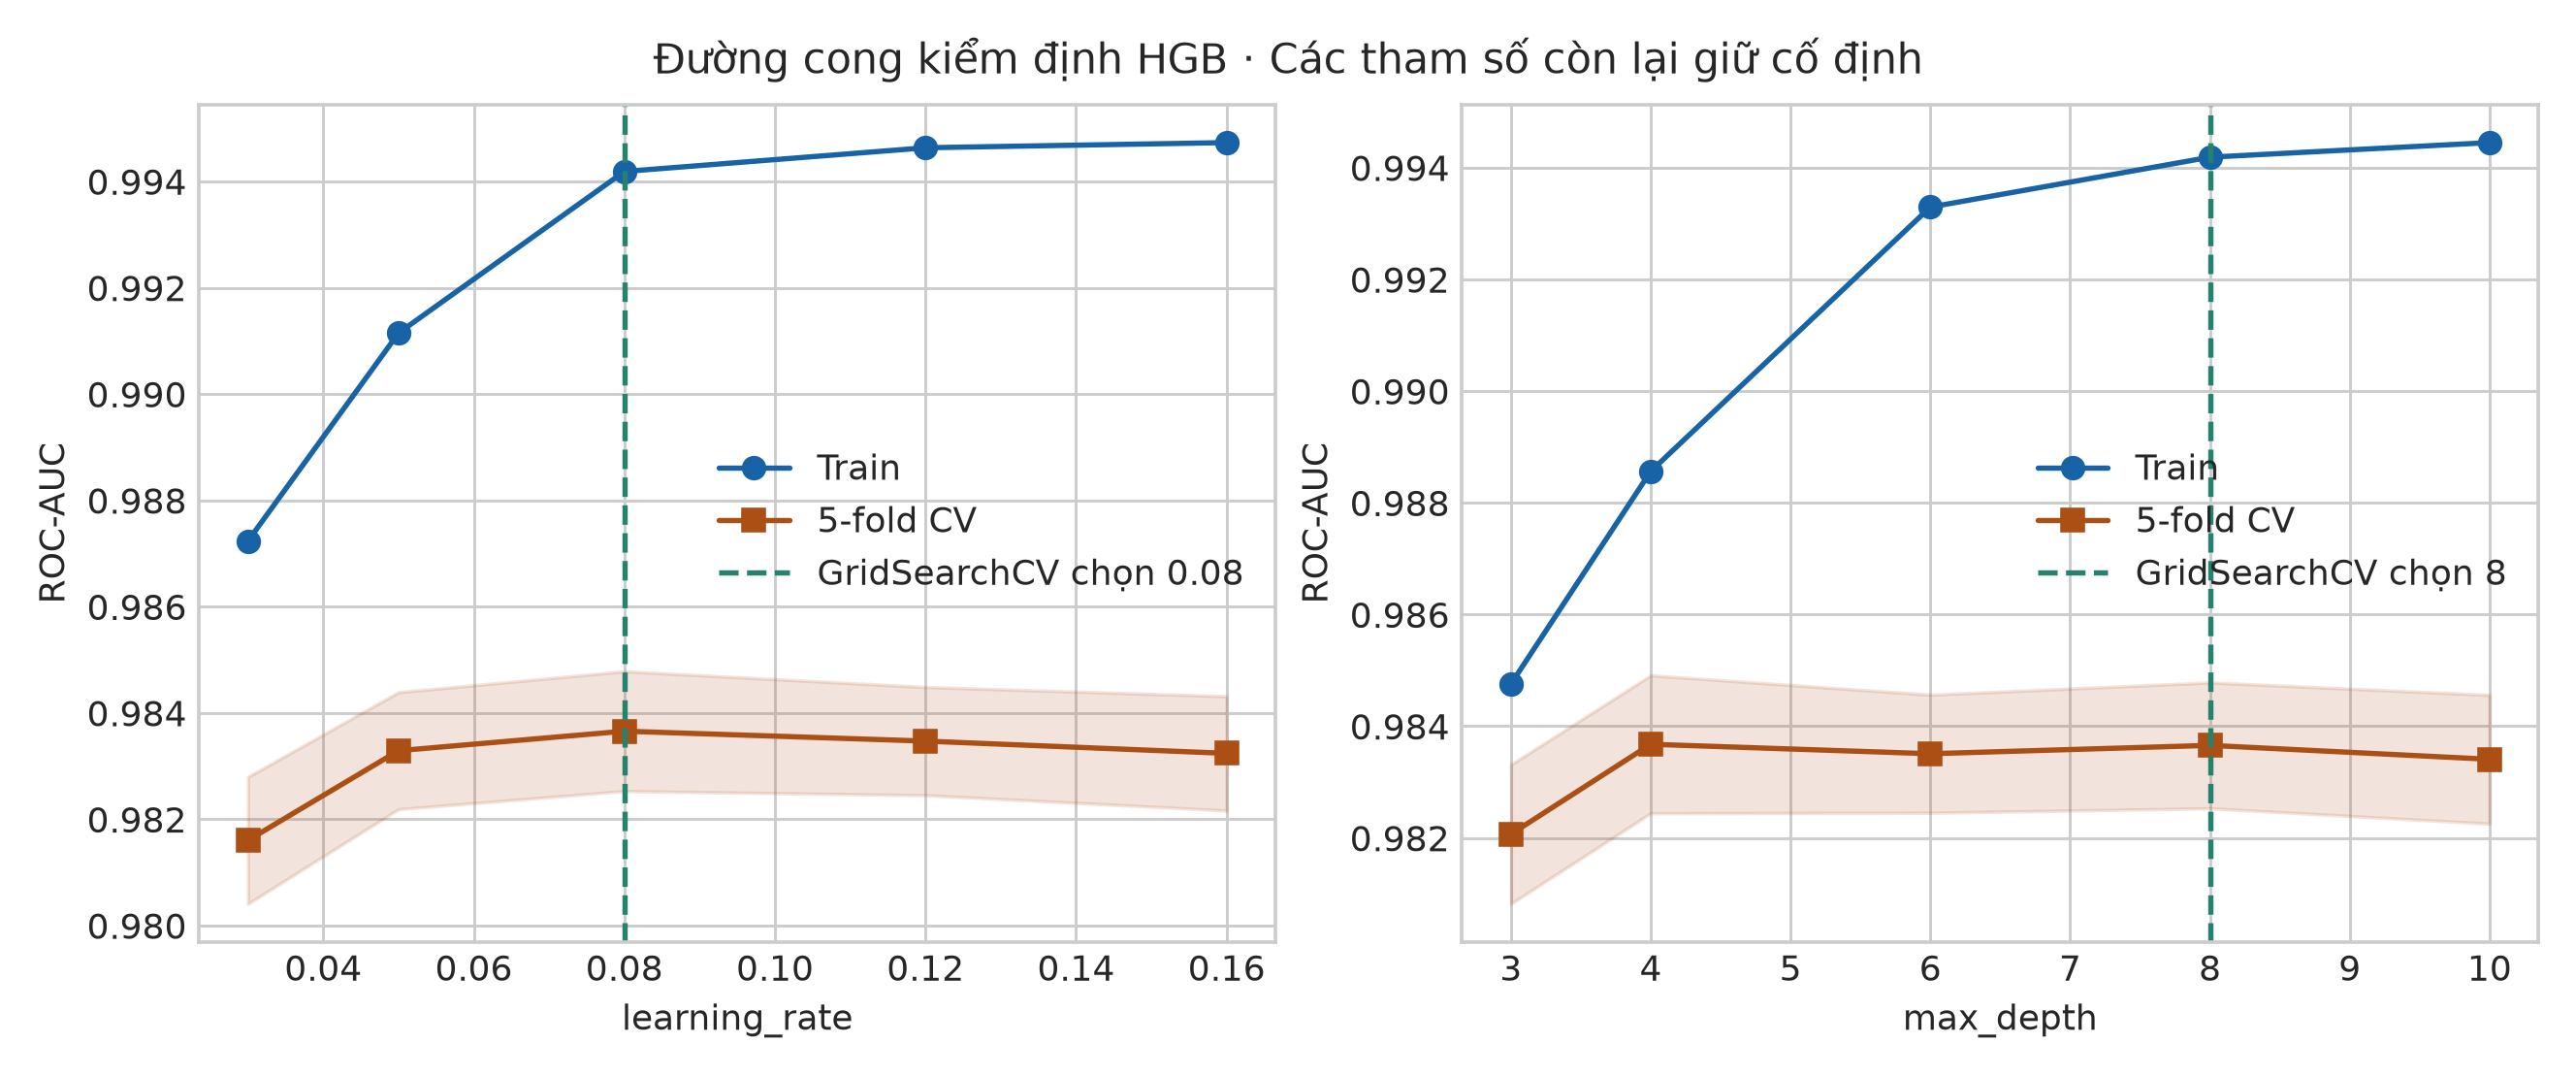

In [3]:
display(Image(filename=str(ROOT / "images" / "duong_cong_kiem_dinh_hyperparameter.png"), width=900))

## Ablation trên cùng các fold

Mỗi hàng lấy điểm cấu hình sau trừ điểm cấu hình trước. Hai hàng đầu
giữ nguyên thuật toán và chỉ thêm đặc trưng. Các hàng đổi thuật toán
giữ tập đặc trưng. Hàng tối ưu so cùng họ HGB trước và sau GridSearchCV.

,So sánh,AUC trước,AUC sau,Δ ROC-AUC,Δ Accuracy (điểm %),Δ F1-Macro
0,Thêm đặc trưng cho Logistic,0.94567,0.94661,0.00094,0.19429,0.00196
1,Thêm đặc trưng cho HGB,0.98360,0.98337,-0.00023,0.01714,0.00020
2,CART → Random Forest,0.94068,0.96846,0.02779,2.57429,0.02614
3,Random Forest → HGB,0.96846,0.98337,0.01491,2.75143,0.02815
4,Tối ưu siêu tham số HGB,0.98337,0.98366,0.00028,-0.03429,-0.00032
5,HGB tối ưu → Stacking,0.98366,0.98260,-0.00105,-0.00286,-0.00001


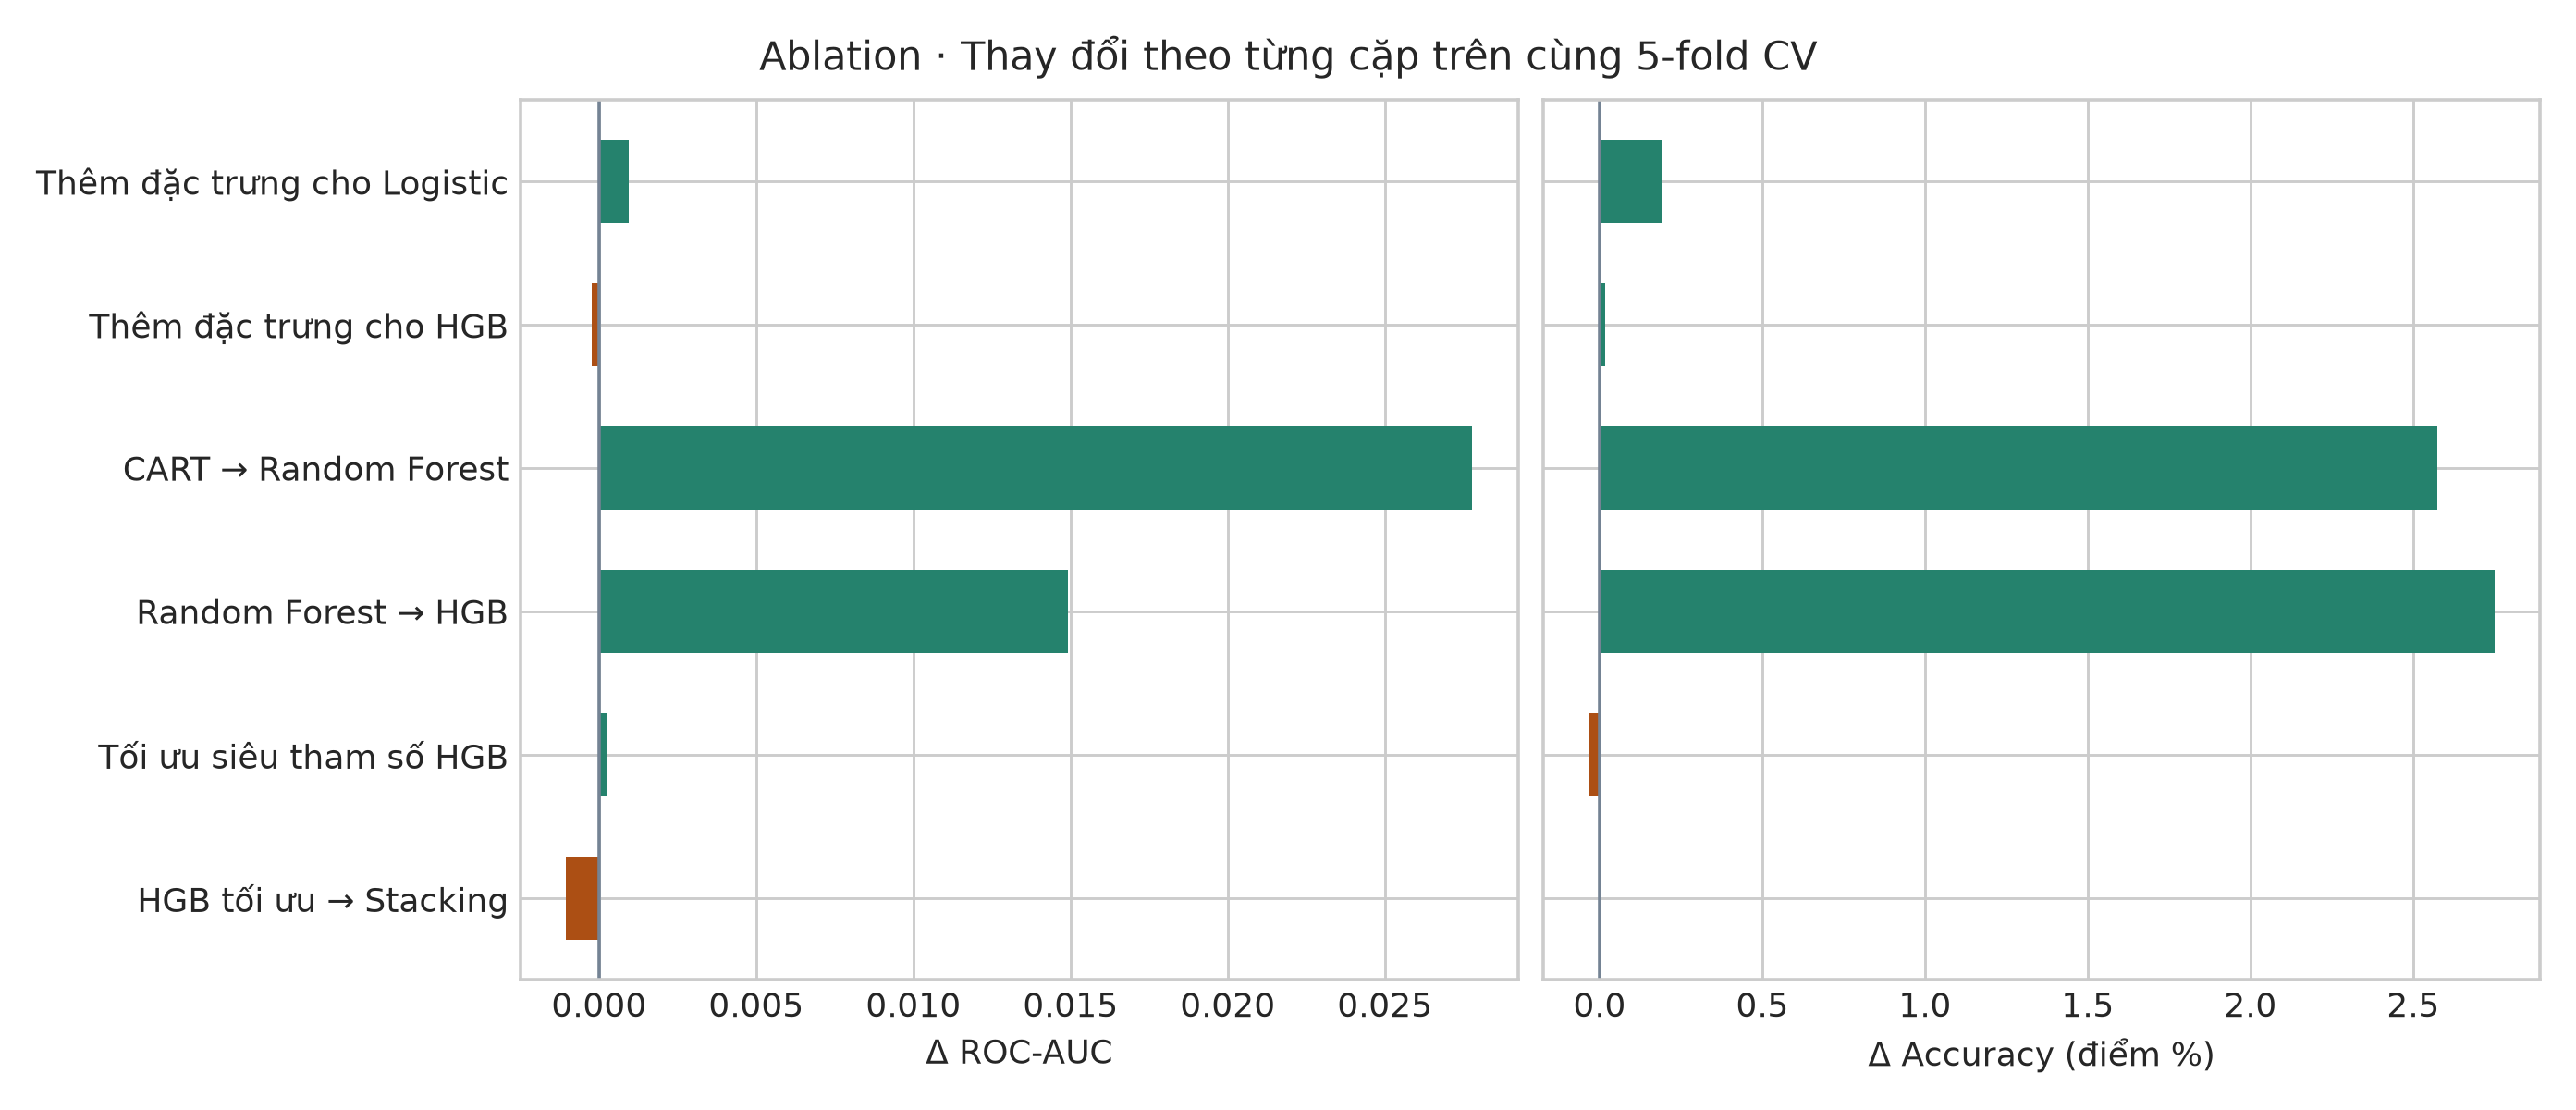

In [4]:
columns = ["So sánh", "AUC trước", "AUC sau", "Δ ROC-AUC",
           "Δ Accuracy (điểm %)", "Δ F1-Macro"]
display(pd.DataFrame(summary["ablation_study"])[columns].round(5))
display(Image(filename=str(ROOT / "images" / "ablation_study_kt3.png"), width=920))

Điểm CV của cấu hình tối ưu dùng chung các fold đã phục vụ tìm kiếm.
Đánh giá mô hình đã chốt trên Test được trình bày trong notebook 04.